# ft_linear_regression

## Importation des donnees

In [5]:
import csv

mileages, prices = [], []
with open('./dataset/data.csv') as f:
    for row in csv.DictReader(f):
        mileages.append(float(row['mileage']))
        prices.append(float(row['price']))

print(f"Test de la recuperation des donnees : \n Les kilometrages : \n{mileages} \nLes prices : \n{prices}")

Test de la recuperation des donnees : 
 Les kilometrages : 
[240000.0, 139800.0, 150500.0, 185530.0, 176000.0, 114800.0, 166800.0, 89000.0, 144500.0, 84000.0, 82029.0, 63060.0, 74000.0, 97500.0, 67000.0, 76025.0, 48235.0, 93000.0, 60949.0, 65674.0, 54000.0, 68500.0, 22899.0, 61789.0] 
Les prices : 
[3650.0, 3800.0, 4400.0, 4450.0, 5250.0, 5350.0, 5800.0, 5990.0, 5999.0, 6200.0, 6390.0, 6390.0, 6600.0, 6800.0, 6800.0, 6900.0, 6900.0, 6990.0, 7490.0, 7555.0, 7990.0, 7990.0, 7990.0, 8290.0]


# Visualisation des donnees sur un nuage de donnees

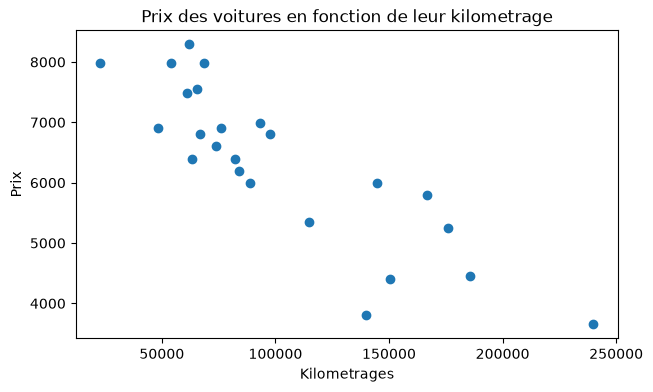

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,4))
plt.scatter(mileages, prices)
plt.xlabel("Kilometrages")
plt.ylabel("Prix")
plt.title("Prix des voitures en fonction de leur kilometrage")
plt.show()


## Hypothese et descente de gradient

In [28]:
# Model / Hypothese
def estimatedPrice(data_feature, theta0, theta1):
    return theta0 + theta1 * data_feature

# Fonction cout
def cost_function(data_feature, prices, theta0, theta1):
    m = len(data_feature)
    total = 0
    for x, y in zip(data_feature, prices):
        error = estimatedPrice(x, theta0, theta1) - y
        total += error ** 2
    return total / (2 * m)

# Descente de gradient
def gradient_descent_step(data_feature, prices, theta0, theta1, learning_rate):
    m = len(data_feature)
    sum0 = sum1 = 0
    for x, y in zip(data_feature, prices):
        error = estimatedPrice(x, theta0, theta1) - y
        sum0 += error
        sum1 += error * x
    tmp0 = learning_rate * sum0 / m
    tmp1 = learning_rate * sum1 / m
    return theta0 - tmp0, theta1 - tmp1



## Entrainement du model (Determination des parametre theta0 et theta1 adequat)

lr = 0.1 -> theta0 = nan theta1 = nan
coût au fil des itérations : [2.1870244928548353e+25, 3.624408871170061e+43, 6.006489505871382e+61, 9.954151826280042e+79, 1.6496347572700803e+98, 2.7338289388042113e+116] ...


<function matplotlib.pyplot.show(close=None, block=None)>

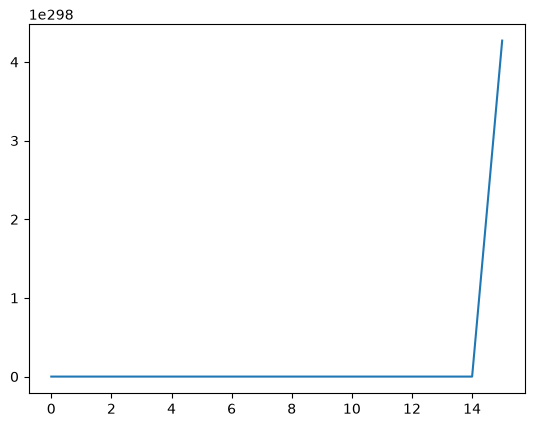

In [32]:
import math

def train(data_feature, prices, learning_rate, iterations):
    theta0 = theta1 = 0.0
    cost_history = []
    for _ in range(iterations):
        try:
            theta0, theta1 = gradient_descent_step(data_feature, prices, theta0, theta1, learning_rate)
            cost_history.append(cost_function(data_feature, prices, theta0, theta1))
        except OverflowError:
            cost_history.append(float('inf'))
            theta0 = theta1 = float('nan')
            break
        if not math.isfinite(cost_history[-1]):
            break
    return theta0, theta1, cost_history


# Test avec un learning rate de 0.1
t0, t1, h = train(mileages, prices, 0.1, 50)
print('lr = 0.1 ->', 'theta0 =', t0, 'theta1 =', t1)
print('coût au fil des itérations :', h[:6], '...')

plt.plot(h)
plt.show

lr = 1e-11, 100 000 itérations -> theta0 = 0.0018 theta1 = 0.04528
coût final : 7683671.4


<function matplotlib.pyplot.show(close=None, block=None)>

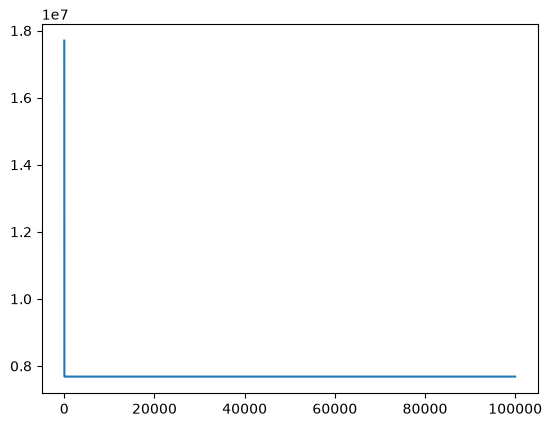

In [33]:
# On cherche un lr qui ne diverge pas : il faut descendre autour de 1e-11
t0, t1, h = train(mileages, prices, 1e-11, 100000)
print('lr = 1e-11, 100 000 itérations ->', 'theta0 =', round(t0, 4), 'theta1 =', round(t1, 6))
print('coût final :', round(h[-1], 1))

plt.plot(h)
plt.show